# Chapter 7 - Picturing Neural Networks: Visualizing Neural Networks

## Summary
Chapter 7 gives mental pictures for everything learned so far, so complex networks become easy to reason about.
- **Simplest visualization:** layers as vertical bars/boxes, weights as lines between them.
- **Letters vs. numbers:** a network is a chain of *vector-matrix multiplications*; layers are vectors (`layer_0`, `layer_1`...) and weights are matrices (`weights_0_1`...).
- **Linking variables:** variable names such as `weights_0_1` show which layers they connect; shapes must line up (`(1,3) . (3,4) -> (1,4)`).
- **Everything together** - forward prop, nonlinearity, backprop, weight updates - can be drawn as one diagram.
- **Why visualize:** it lets you design architectures, spot shape bugs, and think at a higher level without equations.

## Theory
- **Vector-matrix multiplication:** a layer of size *n* connected to a layer of size *m* needs a weight matrix `n x m`.
- **Shape rule:** `(a, b) . (b, c) = (a, c)`; inner dimensions must match.
- **Notation used in the book:** `layer_0` = input, `layer_2` = output; `weights_i_j` connects layer i to j.
- **Batch view:** stacking several samples gives a matrix `(batch, features)`, and the same weights apply to all rows.

In [1]:
# If numpy / scikit-learn are missing in this kernel, uncomment:
# %pip install numpy scikit-learn
import numpy as np

In [2]:
# A 3-layer network and its shapes: 3 -> 4 -> 1
np.random.seed(1)
layer_0 = np.array([[8.5, 0.65, 1.2]])        # (1,3)
weights_0_1 = np.random.randn(3, 4)           # (3,4)
weights_1_2 = np.random.randn(4, 1)           # (4,1)
layer_1 = layer_0.dot(weights_0_1)            # (1,4)
layer_2 = layer_1.dot(weights_1_2)            # (1,1)
for n, a in [("layer_0", layer_0), ("weights_0_1", weights_0_1), ("layer_1", layer_1),
             ("weights_1_2", weights_1_2), ("layer_2", layer_2)]:
    print(f"{n:12s} shape={a.shape}")

layer_0      shape=(1, 3)
weights_0_1  shape=(3, 4)
layer_1      shape=(1, 4)
weights_1_2  shape=(4, 1)
layer_2      shape=(1, 1)


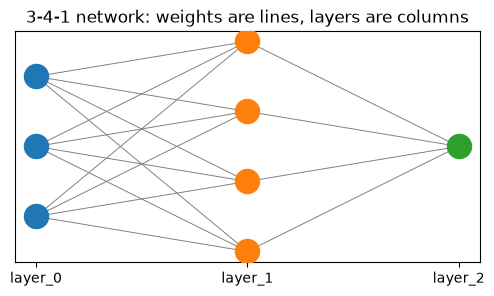

In [3]:
# Draw the architecture as a diagram with matplotlib
import matplotlib.pyplot as plt
sizes = [3, 4, 1]
fig, ax = plt.subplots(figsize=(6, 3))
pos = [[(i, j - (s - 1) / 2) for j in range(s)] for i, s in enumerate(sizes)]
for a, b in zip(pos[:-1], pos[1:]):
    for (x0, y0) in a:
        for (x1, y1) in b:
            ax.plot([x0, x1], [y0, y1], c="gray", lw=0.7)
for layer in pos:
    ax.scatter(*zip(*layer), s=300, zorder=3)
ax.set_xticks([0, 1, 2]); ax.set_xticklabels(["layer_0", "layer_1", "layer_2"])
ax.set_yticks([]); ax.set_title("3-4-1 network: weights are lines, layers are columns")
plt.show()

In [4]:
# Batch view: 4 samples at once -> (4,3) . (3,4) . (4,1)
batch = np.array([[8.5, 0.65, 1.2], [9.5, 0.8, 1.3], [9.9, 0.8, 0.5], [9.0, 0.9, 1.0]])
out = batch.dot(weights_0_1).dot(weights_1_2)
print(batch.shape, "->", out.shape)
print(out.ravel())

(4, 3) -> (4, 1)
[ 9.40978239 10.60704316  7.59083929  9.62784146]


## Takeaways
Think of a network as layers (vectors) joined by weight matrices. Getting shapes right and being able to draw the network is the key skill for the rest of the book.